In [1]:
%load_ext autoreload
%autoreload 2


from index.inverted_index import Index
from index.documents import load_dataset, tokenizer

msmarco = load_dataset("msmarco-passage/dev/judged")

NUM_DOCS = 10000
# K = 10

## Create the inverting index using shuffle

In [2]:
import random
from index.ordered_dataset import OrderedDataset

docs = []
for i, doc in enumerate(msmarco.docs_iter()):
    docs.append(doc)
    if i == NUM_DOCS - 1:
        break

order = list(range(1, NUM_DOCS + 1))
random.shuffle(order)

random_dataset = OrderedDataset(docs, order)

# for doc in random_dataset.docs_iter():
#     print(doc)


unordered_index = Index()
unordered_index.build_index(random_dataset, tokenizer, max_num_docs=NUM_DOCS)

Processing:   90.0% [9000/10000] | Current docid: 9000                

## Creating the tf-idf matrix

In [3]:
from index.reorder_utils import create_sparse_tf_idf_matrix
import pandas as pd

tf_idf_matrix, doc_ids, terms = create_sparse_tf_idf_matrix(unordered_index)
df = pd.DataFrame.sparse.from_spmatrix(tf_idf_matrix, index=doc_ids, columns=terms)


In [8]:
# from time import perf_counter
# def vary_compression_type(index, method):

#     if method == "pfor_delta":
#         start = perf_counter()
#         # TODO we should optimize these parameters...
#         unordered_index.compress_index("pfor_delta",k=8, block_size=128, extra_strategy="None")

#         elapsed_time = perf_counter() - start
#         return index.get_approx_size(), elapsed_time
    
#     start = perf_counter()
    
#     unordered_index.compress_index(method)

#     elapsed_time = perf_counter() - start
    
#     return index.get_approx_size(), elapsed_time



In [4]:
import warnings
from sklearn.exceptions import DataConversionWarning

warnings.filterwarnings("ignore", category=DataConversionWarning)

In [5]:
from time import perf_counter
import copy

def prepare_index(src_index, method):
    idx = copy.deepcopy(src_index)
    
    if not src_index.removed_tf : # TODO remember to optimize the parameters of the pfordelta!!
        idx.remove_tf()

    start = perf_counter()

    idx.compress_index(method)

    elapsed_time = perf_counter() - start
    
    return idx.get_approx_size(), elapsed_time


In [6]:
from index.reorder_utils import k_medoids, reorder_documents_by_tsp, tsp_path, calculate_distance_matrix
def TSP_order(df,k):

    print(f"using {k} total clusters")
    medoids, medoids_id, cluster_to_docs = k_medoids(df, k)
    
    dist_matrix = calculate_distance_matrix(medoids, method="jaccard")
    tsp_path_ = tsp_path(dist_matrix)
    new_order = reorder_documents_by_tsp(tsp_path_,cluster_to_docs, medoids_id)
    ordered_dataset = OrderedDataset(docs, new_order)

    return ordered_dataset


## Experiment varying the k

In [13]:
import copy


"""
For each k we store the stats for each compression type.
"""

K = [10,20,50,60,80,100,120,150,170,200]

time_unordered_gamma = []
time_ordered_gamma = []
results_unordered_gamma = []
results_ordered_gamma = []

time_unordered_delta = []
time_ordered_delta = []
results_unordered_delta = []
results_ordered_delta = []

time_unordered_var_byte = []
time_ordered_var_byte = []
results_unordered_var_byte = []
results_ordered_var_byte = []

time_unordered_pfor_delta = []
time_ordered_pfor_delta = []
results_unordered_pfor_delta = []
results_ordered_pfor_delta = []

unordered_index = Index()
unordered_index.clear_index()
unordered_index.build_index(random_dataset,tokenizer,max_num_docs=NUM_DOCS,d_gap=True)

for k in K:

    reordered_index = Index()
    reordered_index.clear_index()
    reordered_index.build_index(TSP_order(df,k),tokenizer,max_num_docs=NUM_DOCS,d_gap=True)

    # compression stat for unordered index
    
    gamma_index_stat_unordered, gamma_time_unordered = prepare_index(unordered_index, "gamma")
    delta_index_stat_unordered, delta_time_unordered = prepare_index(unordered_index, "delta")
    vb_index_stat_unordered , vb_time_unordered= prepare_index(unordered_index, "varbyte")
    pfor_index_stat_unordered, pfor_time_unordered = prepare_index(unordered_index, "pfor_delta")

    results_unordered_gamma.append(gamma_index_stat_unordered)
    time_unordered_gamma.append(gamma_time_unordered)

    results_unordered_delta.append(delta_index_stat_unordered)
    time_unordered_delta.append(delta_time_unordered)

    results_unordered_var_byte.append(vb_index_stat_unordered)
    time_unordered_var_byte.append(vb_time_unordered)

    results_unordered_pfor_delta.append(pfor_index_stat_unordered)
    time_unordered_pfor_delta.append(pfor_time_unordered)
    
    # compression stat for ordered index

    gamma_index_stat_ordered, gamma_time_ordered = prepare_index(reordered_index, "gamma")
    delta_index_stat_ordered, delta_time_ordered = prepare_index(reordered_index, "delta")
    vb_index_stat_ordered , vb_time_ordered= prepare_index(reordered_index, "varbyte")
    pfor_index_stat_ordered, pfor_time_ordered = prepare_index(reordered_index, "pfor_delta")

    results_ordered_gamma.append(gamma_index_stat_ordered)
    time_ordered_gamma.append(gamma_time_ordered)

    results_ordered_delta.append(delta_index_stat_ordered)
    time_ordered_delta.append(delta_time_ordered)

    results_ordered_var_byte.append(vb_index_stat_ordered)
    time_ordered_var_byte.append(vb_time_ordered)

    results_ordered_pfor_delta.append(pfor_index_stat_ordered)
    time_ordered_pfor_delta.append(pfor_time_ordered)



Processing:   90.0% [9000/10000] | Current docid: 9000                using 10 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 20 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 50 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 60 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False
using 80 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompress

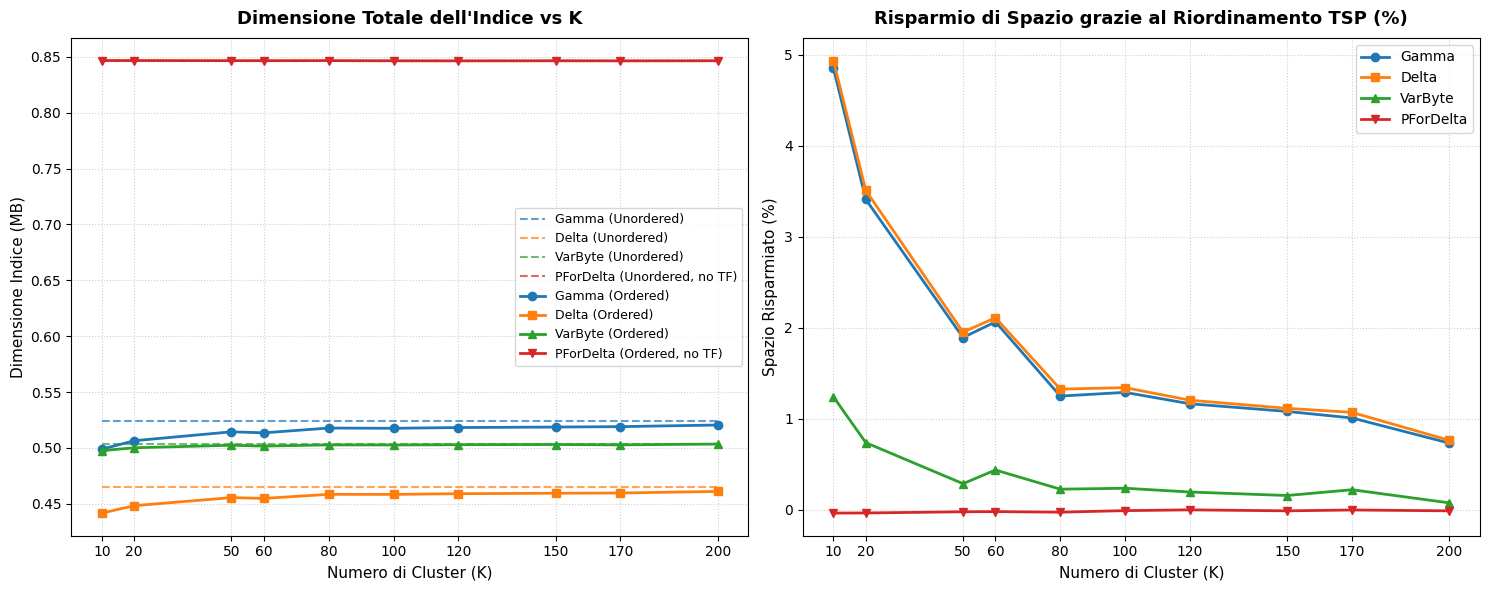

In [14]:
import matplotlib.pyplot as plt

# 1. Estrazione dei dati (convertiti in Megabyte per una migliore leggibilità)
# Dividiamo per 1024**2 per convertire da Byte a Megabyte (MB)
MB_FACTOR = 1024 ** 2


# Unordered
un_gamma = [res["total_bytes"] / MB_FACTOR for res in results_unordered_gamma]
un_delta = [res["total_bytes"] / MB_FACTOR for res in results_unordered_delta]
un_varbyte = [res["total_bytes"] / MB_FACTOR for res in results_unordered_var_byte]
un_pfor = [res["total_bytes"] / MB_FACTOR for res in results_unordered_pfor_delta]

# Ordered
or_gamma = [res["total_bytes"] / MB_FACTOR for res in results_ordered_gamma]
or_delta = [res["total_bytes"] / MB_FACTOR for res in results_ordered_delta]
or_varbyte = [res["total_bytes"] / MB_FACTOR for res in results_ordered_var_byte]
or_pfor = [res["total_bytes"] / MB_FACTOR for res in results_ordered_pfor_delta]

# 2. Configurazione della figura con 2 subplot affiancati
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Palette colori coerente per ogni algoritmo
colors = {
    'Gamma': '#1f77b4', 
    'Delta': '#ff7f0e', 
    'VarByte': '#2ca02c', 
    'PForDelta': '#d62728'
}

# -----------------------------------------------------------------
# GRAFICO 1: Dimensioni Assolute dell'Indice
# -----------------------------------------------------------------
# Linee tratteggiate = Unordered (saranno linee piatte)
ax1.plot(K, un_gamma, linestyle='--', color=colors['Gamma'], alpha=0.7, label='Gamma (Unordered)')
ax1.plot(K, un_delta, linestyle='--', color=colors['Delta'], alpha=0.7, label='Delta (Unordered)')
ax1.plot(K, un_varbyte, linestyle='--', color=colors['VarByte'], alpha=0.7, label='VarByte (Unordered)')
ax1.plot(K, un_pfor, linestyle='--', color=colors['PForDelta'], alpha=0.7, label='PForDelta (Unordered, no TF)')

# Linee continue con marker = Ordered (variano al variare di K)
ax1.plot(K, or_gamma, marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma (Ordered)')
ax1.plot(K, or_delta, marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta (Ordered)')
ax1.plot(K, or_varbyte, marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte (Ordered)')
ax1.plot(K, or_pfor, marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta (Ordered, no TF)')

ax1.set_title("Dimensione Totale dell'Indice vs K", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Numero di Cluster (K)", fontsize=11)
ax1.set_ylabel("Dimensione Indice (MB)", fontsize=11)
ax1.set_xticks(K)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=9, loc='best', frameon=True)

# -----------------------------------------------------------------
# GRAFICO 2: Risparmio Percentuale di Spazio
# -----------------------------------------------------------------
def get_savings(unordered_list, ordered_list):
    return [(un - o) / un * 100 for un, o in zip(unordered_list, ordered_list)]

ax2.plot(K, get_savings(un_gamma, or_gamma), marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma')
ax2.plot(K, get_savings(un_delta, or_delta), marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta')
ax2.plot(K, get_savings(un_varbyte, or_varbyte), marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte')
ax2.plot(K, get_savings(un_pfor, or_pfor), marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta')

ax2.set_title("Risparmio di Spazio grazie al Riordinamento TSP (%)", fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel("Numero di Cluster (K)", fontsize=11)
ax2.set_ylabel("Spazio Risparmiato (%)", fontsize=11)
ax2.set_xticks(K)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=10, loc='best', frameon=True)

# Ottimizzazione del layout e salvataggio
plt.tight_layout()


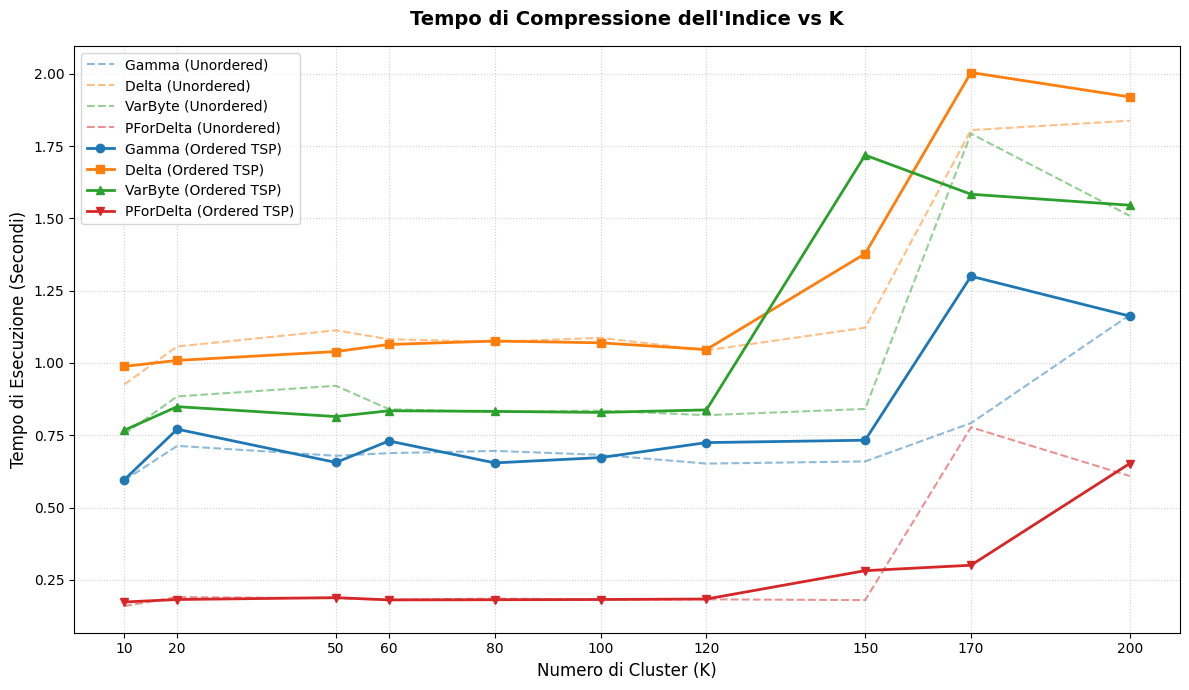

In [15]:
import matplotlib.pyplot as plt

# 1. Recupero dei tempi (Prendiamo gli ultimi N elementi coerenti con K)
N = len(K)

# Tempi Unordered (Linee tratteggiate - costanti rispetto a K)
t_un_gamma = time_unordered_gamma[-N:]
t_un_delta = time_unordered_delta[-N:]
t_un_varbyte = time_unordered_var_byte[-N:]
t_un_pfor = time_unordered_pfor_delta[-N:]

# Tempi Ordered TSP (Linee continue - variano con K)
t_or_gamma = time_ordered_gamma[-N:]
t_or_delta = time_ordered_delta[-N:]
t_or_varbyte = time_ordered_var_byte[-N:]
t_or_pfor = time_ordered_pfor_delta[-N:]

# 2. Configurazione del Grafico delle Linee Temporali
plt.figure(figsize=(12, 7))

# Palette colori coerente con il grafico delle dimensioni
colors = {
    'Gamma': '#1f77b4', 
    'Delta': '#ff7f0e', 
    'VarByte': '#2ca02c', 
    'PForDelta': '#d62728'
}

# --- Plot Unordered (Tratteggiati) ---
plt.plot(K, t_un_gamma, linestyle='--', color=colors['Gamma'], alpha=0.5, label='Gamma (Unordered)')
plt.plot(K, t_un_delta, linestyle='--', color=colors['Delta'], alpha=0.5, label='Delta (Unordered)')
plt.plot(K, t_un_varbyte, linestyle='--', color=colors['VarByte'], alpha=0.5, label='VarByte (Unordered)')
plt.plot(K, t_un_pfor, linestyle='--', color=colors['PForDelta'], alpha=0.5, label='PForDelta (Unordered)')

# --- Plot Ordered (Linee Continue con Marker) ---
plt.plot(K, t_or_gamma, marker='o', linestyle='-', color=colors['Gamma'], linewidth=2, label='Gamma (Ordered TSP)')
plt.plot(K, t_or_delta, marker='s', linestyle='-', color=colors['Delta'], linewidth=2, label='Delta (Ordered TSP)')
plt.plot(K, t_or_varbyte, marker='^', linestyle='-', color=colors['VarByte'], linewidth=2, label='VarByte (Ordered TSP)')
plt.plot(K, t_or_pfor, marker='v', linestyle='-', color=colors['PForDelta'], linewidth=2, label='PForDelta (Ordered TSP)')

# Personalizzazione estetica
plt.title("Tempo di Compressione dell'Indice vs K", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Numero di Cluster (K)", fontsize=12)
plt.ylabel("Tempo di Esecuzione (Secondi)", fontsize=12)
plt.xticks(K)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='best', frameon=True)

# Mostra il grafico
plt.tight_layout()
plt.show()

## D-Gap vs no D-Gap

In [16]:
import copy
from index.reorder_utils import k_medoids, reorder_documents_by_tsp, tsp_path, calculate_distance_matrix


K = 50

time_no_d_gap_gamma = []
time_d_gap_gamma = []
results_no_d_gap_gamma = []
results_d_gap_gamma = []

time_no_d_gap_delta = []
time_d_gap_delta = []
results_no_d_gap_delta = []
results_d_gap_delta = []

time_no_d_gap_var_byte = []
time_d_gap_var_byte = []
results_no_d_gap_var_byte = []
results_d_gap_var_byte = []

time_no_d_gap_pfor_delta = []
time_d_gap_pfor_delta = []
results_no_d_gap_pfor_delta = []
results_d_gap_pfor_delta = []


ordered_dataset = TSP_order(df,K)


# no d-gap index
no_d_gap_index = Index()
no_d_gap_index.clear_index()
no_d_gap_index.build_index(ordered_dataset,tokenizer,max_num_docs=NUM_DOCS,d_gap=False)

# d-gap index
d_gap_index = Index()
d_gap_index.clear_index()
d_gap_index.build_index(ordered_dataset,tokenizer,max_num_docs=NUM_DOCS, d_gap=True)


# compression stat for unordered index

gamma_index_stat_no_d_gap, gamma_time_no_d_gap = prepare_index(no_d_gap_index, "gamma")
delta_index_stat_no_d_gap, delta_time_no_d_gap = prepare_index(no_d_gap_index, "delta")
vb_index_stat_no_d_gap , vb_time_no_d_gap= prepare_index(no_d_gap_index, "varbyte")
pfor_index_stat_no_d_gap, pfor_time_no_d_gap = prepare_index(no_d_gap_index, "pfor_delta")

results_no_d_gap_gamma.append(gamma_index_stat_no_d_gap)
time_no_d_gap_gamma.append(gamma_time_no_d_gap)

results_no_d_gap_delta.append(delta_index_stat_no_d_gap)
time_no_d_gap_delta.append(delta_time_no_d_gap)

results_no_d_gap_var_byte.append(vb_index_stat_no_d_gap)
time_no_d_gap_var_byte.append(vb_time_no_d_gap)

results_no_d_gap_pfor_delta.append(pfor_index_stat_no_d_gap)
time_no_d_gap_pfor_delta.append(pfor_time_no_d_gap)

# compression stat for ordered index

gamma_index_stat_d_gap, gamma_time_d_gap = prepare_index(d_gap_index, "gamma")
delta_index_stat_d_gap, delta_time_d_gap = prepare_index(d_gap_index, "delta")
vb_index_stat_d_gap , vb_time_d_gap= prepare_index(d_gap_index, "varbyte")
pfor_index_stat_d_gap, pfor_time_d_gap = prepare_index(d_gap_index, "pfor_delta")

results_d_gap_gamma.append(gamma_index_stat_d_gap)
time_d_gap_gamma.append(gamma_time_d_gap)

results_d_gap_delta.append(delta_index_stat_d_gap)
time_d_gap_delta.append(delta_time_d_gap)

results_d_gap_var_byte.append(vb_index_stat_d_gap)
time_d_gap_var_byte.append(vb_time_d_gap)

results_d_gap_pfor_delta.append(pfor_index_stat_d_gap)
time_d_gap_pfor_delta.append(pfor_time_d_gap)



using 50 total clusters
Processing:   90.0% [9000/10000] | Current docid: 9000                Handling PForDelta with is_decompressing=False
Handling PForDelta with is_decompressing=False


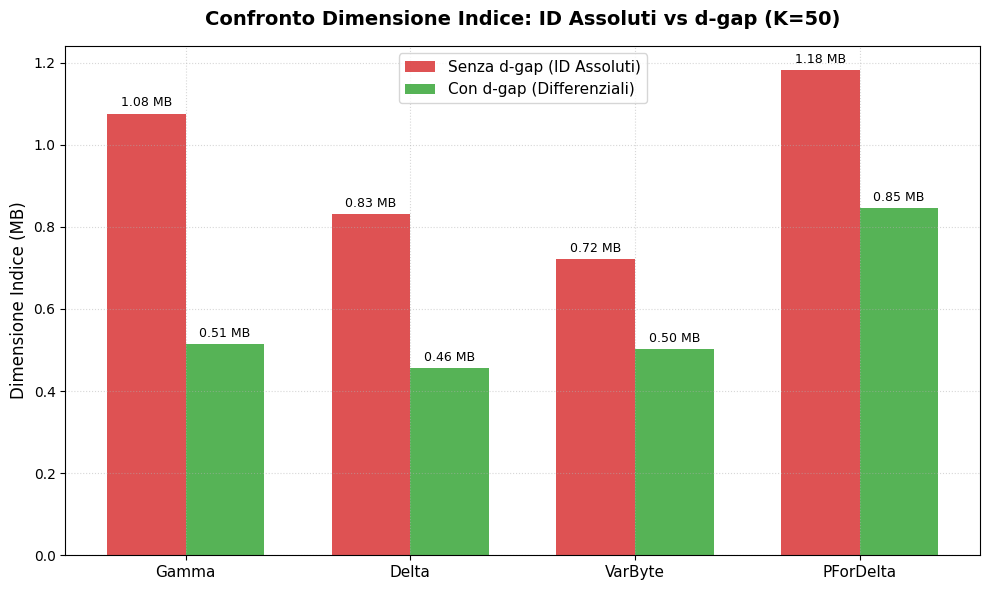

In [17]:
import matplotlib.pyplot as plt
import numpy as np

MB_FACTOR = 1024 ** 2
algoritmi = ['Gamma', 'Delta', 'VarByte', 'PForDelta']

# Estrazione delle dimensioni (prendiamo il primo e unico elemento, dato che K=50 è fisso)
size_no_dgap = [
    results_no_d_gap_gamma[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_delta[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_var_byte[0]["total_bytes"] / MB_FACTOR,
    results_no_d_gap_pfor_delta[0]["total_bytes"] / MB_FACTOR
]

size_dgap = [
    results_d_gap_gamma[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_delta[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_var_byte[0]["total_bytes"] / MB_FACTOR,
    results_d_gap_pfor_delta[0]["total_bytes"] / MB_FACTOR
]

x = np.arange(len(algoritmi))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, size_no_dgap, width, label='Senza d-gap (ID Assoluti)', color='#d62728', alpha=0.8)
rects2 = ax.bar(x + width/2, size_dgap, width, label='Con d-gap (Differenziali)', color='#2ca02c', alpha=0.8)

ax.set_title("Confronto Dimensione Indice: ID Assoluti vs d-gap (K=50)", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Dimensione Indice (MB)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(algoritmi, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)

# Aggiunge i valori sopra le barre
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f} MB',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

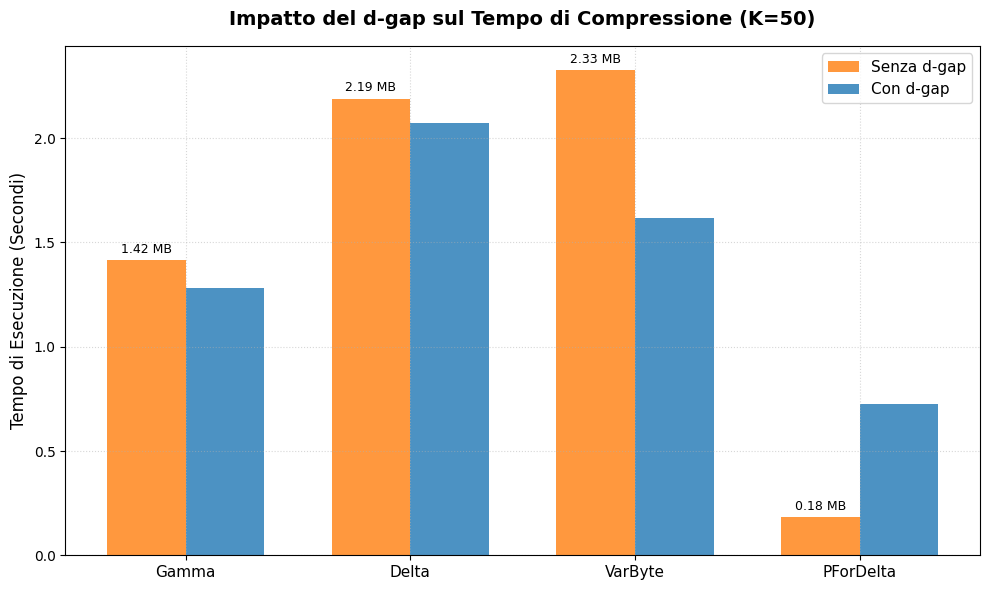

In [18]:
time_no_dgap = [time_no_d_gap_gamma[0], time_no_d_gap_delta[0], time_no_d_gap_var_byte[0], time_no_d_gap_pfor_delta[0]]
time_dgap = [time_d_gap_gamma[0], time_d_gap_delta[0], time_d_gap_var_byte[0], time_d_gap_pfor_delta[0]]

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, time_no_dgap, width, label='Senza d-gap', color='#ff7f0e', alpha=0.8)
rects2 = ax.bar(x + width/2, time_dgap, width, label='Con d-gap', color='#1f77b4', alpha=0.8)

ax.set_title("Impatto del d-gap sul Tempo di Compressione (K=50)", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Tempo di Esecuzione (Secondi)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(algoritmi, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)

autolabel(rects1) # Puoi riutilizzare la funzione precedente cambiando solo l'unità di misura in 's' se necessario
plt.tight_layout()
plt.show()

## Decompression experiment

In [7]:
from time import perf_counter
import copy

def decompress_list(src_index, method):
    idx = copy.deepcopy(src_index)
    
    if not src_index.removed_tf : # TODO remember to optimize the parameters of the pfordelta!!
        idx.remove_tf()

    idx.compress_index(method)
    start = perf_counter()
    idx.decompress_index(method)
    elapsed_time = perf_counter() - start
    
    return idx.get_approx_size(), elapsed_time

In [13]:
from time import perf_counter
import copy

# =========================================================================
# 1. IDENTIFICAZIONE DEI 10 TERMINI TOP (POSTINGS PIÙ LUNGHE)
# =========================================================================
# Assumiamo che 'reordered_index' sia il tuo indice principale calcolato con TSP e d-gap
top_terms = sorted(
    reordered_index.index.keys(), 
    key=lambda term: len(reordered_index.index[term]), 
    reverse=True
)[:100]

print("Termini più frequenti selezionati per il test:", top_terms)

# Estraiamo il sotto-dizionario con solo le postings list di questi 10 termini
top_terms_postings = {term: reordered_index.index[term] for term in top_terms}

# Dizionario in cui salveremo i tempi di decompressione
decompression_benchmarks = {}

# Elenco dei metodi richiesti dalla consegna
metodi = ["gamma", "delta", "varbyte", "pfor_delta"]

# =========================================================================
# 2. BENCHMARK DI DECOMPRESSIONE
# =========================================================================
for metodo in metodi:
    # Creiamo un oggetto Index fresco per questo specifico metodo
    test_index = Index()
    test_index.clear_index()
    
    # Configura lo stato dell'indice replicando quello di partenza
    test_index.num_docs = reordered_index.num_docs
    test_index.d_gap_index_ = reordered_index.d_gap_index_
    test_index.removed_tf = reordered_index.removed_tf
    
    # Copiamo le postings list dei 10 termini top (usiamo deepcopy per non sporcare i dati)
    test_index.index = copy.deepcopy(top_terms_postings)
    
    # Compressione del sotto-indice
    # Nota: se usi PForDelta o se il tuo indice richiede remove_tf(), 
    # assicurati che test_index.removed_tf sia True prima di chiamare compress_index
    test_index.remove_tf()
    test_index.compress_index(method=metodo)
    
    # --- MISURAZIONE DELLA DECOMPRESSIONE ---
    start_time = perf_counter()
    test_index.decompress_index()
    end_time = perf_counter()
    
    # Salviamo il tempo impiegato
    execution_time = end_time - start_time
    decompression_benchmarks[metodo] = execution_time
    
    print(f"Tempo di decompressione per {metodo:<10}: {execution_time:.6f} secondi")

# Se vuoi testare anche PForDelta, ricordati di accertarti che le TF siano rimosse
# (PForDelta richiede test_index.removed_tf = True nel tuo controllo a riga 130)

Termini più frequenti selezionati per il test: ['the', 'of', 'and', 'a', 'to', 'in', 'is', 'for', 'that', 'on', 'or', 'are', 'with', 'as', 'by', 'it', 'from', 'you', 'be', 'an', 'this', 'can', 'at', 'your', '1', 'have', 'was', 'not', 'has', 'which', '2', 'if', 'one', 'more', 'but', 'will', 'all', 'also', 'when', 'most', 'other', 'its', '3', 'may', 'about', 'they', 'there', 'than', 'first', 'their', 'some', 'new', 'what', 'used', 'up', 'who', 'into', 'these', 'use', 'i', 'time', 'after', 'years', 'been', 'do', 'only', 'how', 'two', 'so', 'many', 'out', 'his', '4', 'people', 'any', 'we', 'like', 'us', 'states', 'no', 'such', 'make', 'were', 'through', 'state', 'then', 'over', 'get', 'population', 'see', 'he', 'our', 'just', 'name', '5', 'between', 'called', 'number', 'united', 'during']
Tempo di decompressione per gamma     : 0.235590 secondi
Tempo di decompressione per delta     : 0.404653 secondi
Tempo di decompressione per varbyte   : 0.167085 secondi
Handling PForDelta with is_decomp

C:\Users\Utente\AppData\Local\Temp\ipykernel_10368\354505438.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([alg.upper() if alg != 'varbyte' else 'VarByte' for alg in algoritmi])


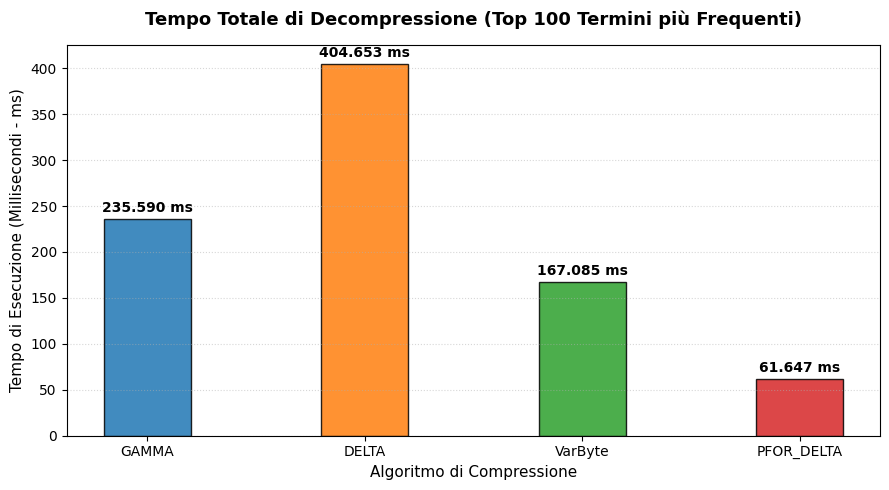

In [16]:
import matplotlib.pyplot as plt

# Recupera i dati dal dizionario dei benchmark salvato nel passo precedente
algoritmi = list(decompression_benchmarks.keys())
tempi = list(decompression_benchmarks.values())

# Convertiamo i tempi in millisecondi per rendere la lettura più immediata sul grafico
tempi_ms = [t * 1000 for t in tempi]

plt.figure(figsize=(9, 5))

# Palette colori coerente (aggiunto un grigio/rosso per l'eventuale PForDelta)
colors = {
    'gamma': '#1f77b4', 
    'delta': '#ff7f0e', 
    'varbyte': '#2ca02c', 
    'pfor_delta': '#d62728'
}
bar_colors = [colors.get(alg, '#7f7f7f') for alg in algoritmi]

# Creazione delle barre
bars = plt.bar(algoritmi, tempi_ms, color=bar_colors, alpha=0.85, edgecolor='black', width=0.4)

# Personalizzazione estetica
plt.title("Tempo Totale di Decompressione (Top 100 Termini più Frequenti)", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Tempo di Esecuzione (Millisecondi - ms)", fontsize=11)
plt.xlabel("Algoritmo di Compressione", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5, axis='y')

# Capitalizza i nomi degli algoritmi sull'asse X per una resa più professionale
plt.gca().set_xticklabels([alg.upper() if alg != 'varbyte' else 'VarByte' for alg in algoritmi])

# Aggiunta del valore esatto sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.3f} ms',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 punti di scostamento verticale
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()

plt.show()

## TODO experiment with 4 milion (keeping k = 50)

In [4]:
import random
from index.ordered_dataset import OrderedDataset

MAX = 4000000


docs = []
for i, doc in enumerate(msmarco.docs_iter()):
    docs.append(doc)
    if i == MAX - 1:
        break

order = list(range(1, MAX + 1))
random.shuffle(order)

random_dataset = OrderedDataset(docs, order)

# for doc in random_dataset.docs_iter():
#     print(doc)


unordered_index = Index()
unordered_index.build_index(random_dataset, tokenizer, max_num_docs=MAX)

Processing:  100.0% [3999000/4000000] | Current docid: 3999000             

In [ ]:
from index.reorder_utils import create_sparse_tf_idf_matrix
import pandas as pd

tf_idf_matrix, doc_ids, terms = create_sparse_tf_idf_matrix(unordered_index)
df = pd.DataFrame.sparse.from_spmatrix(tf_idf_matrix, index=doc_ids, columns=terms)

In [ ]:
from index.reorder_utils import calculate_distance_matrix

print(f"using {k} total clusters")
medoids, medoids_id, cluster_to_docs = k_medoids(df, k)

print(medoids)
dist_matrix = calculate_distance_matrix(medoids, method="jaccard")


 

NameError: name 'medoids' is not defined

## TSP path

In [36]:
from index.reorder_utils import tsp_path

tsp_path = tsp_path(dist_matrix)

print(tsp_path)

[2, 1, 3, 5, 9, 6, 4, 7, 8, 0]


## Reorder

In [38]:
from index.reorder_utils import reorder_documents_by_tsp

new_order = reorder_documents_by_tsp(tsp_path,cluster_to_docs, medoids_id)
print(new_order)

[4, 29, 97, 102, 105, 142, 159, 179, 246, 249, 254, 268, 314, 319, 412, 431, 453, 488, 519, 541, 652, 722, 822, 972, 1005, 1044, 1058, 1064, 1141, 1156, 1180, 1268, 1286, 1291, 1324, 1349, 1403, 1408, 1421, 1424, 1431, 1479, 1529, 1535, 1555, 1570, 1653, 1741, 1770, 1786, 1928, 1929, 1976, 2021, 2089, 2096, 2154, 2165, 2176, 2346, 2396, 2456, 2489, 2493, 2538, 2547, 2571, 2608, 2627, 2639, 2665, 2715, 2739, 2854, 2858, 2860, 2928, 2929, 2969, 2981, 3026, 3081, 3086, 3129, 3138, 3255, 3300, 3338, 3362, 3364, 3372, 3418, 3445, 3481, 3518, 3567, 3601, 3604, 3642, 3685, 3696, 3710, 3771, 3805, 3808, 3871, 3873, 3874, 3951, 3966, 4089, 4136, 4224, 4298, 4306, 4329, 4345, 4406, 4408, 4453, 4569, 4649, 4656, 4707, 4734, 4778, 4799, 4809, 4842, 4856, 4868, 4905, 4995, 4997, 5027, 5073, 5116, 5126, 5166, 5176, 5244, 5257, 5271, 5416, 5441, 5461, 5469, 5551, 5570, 5594, 5702, 5727, 5732, 5757, 5771, 5785, 5877, 5896, 6015, 6019, 6043, 6181, 6186, 6220, 6312, 6466, 6472, 6530, 6595, 6673, 6749, 6

## Experiment

In [44]:

ordered_dataset = OrderedDataset(docs, new_order)

reordered_inverted_index = Index()
reordered_inverted_index.build_index(
    ordered_dataset,
    tokenizer,
    max_num_docs=-1, #! -1 since reordered docs are already limited to 10001 in the original index
    d_gap=True
)

stat_r = reordered_inverted_index.get_approx_size()


unordered_index = Index()
unordered_index.build_index(random_dataset,tokenizer,max_num_docs=-1,d_gap=True)
unordered_index.get_approx_size()



Processing:   90.0% [9000/10000] | Current docid: 9000                
=== Index Size Breakdown ===
Doc ID bits:  12,172,320
TF bits:      12,172,320
Total bits:   24,344,640
Total bytes:  3,043,080.00
Processing:   90.0% [9000/10000] | Current docid: 9000                
=== Index Size Breakdown ===
Doc ID bits:  12,172,320
TF bits:      12,172,320
Total bits:   24,344,640
Total bytes:  3,043,080.00


{'term_bytes': 0,
 'doc_id_bits': 12172320,
 'tf_bits': 12172320,
 'total_bits': 24344640,
 'total_bytes': 3043080.0}

## Compression Ordered by TSP

In [45]:
unordered_index.compress_index("gamma")
unordered_index.get_approx_size()

reordered_inverted_index.compress_index("gamma")
reordered_inverted_index.get_approx_size()








=== Index Size Breakdown ===
Doc ID bits:  4,394,453
TF bits:      583,087
Total bits:   4,977,540
Total bytes:  622,192.50

=== Index Size Breakdown ===
Doc ID bits:  4,221,537
TF bits:      583,087
Total bits:   4,804,624
Total bytes:  600,578.00


{'term_bytes': 0,
 'doc_id_bits': 4221537,
 'tf_bits': 583087,
 'total_bits': 4804624,
 'total_bytes': 600578.0}